# ClusterBP v2, этап 3: интерпретация

Схема по образцу Grubov et al., *IJNS* 2026 (doi:10.1142/S0129065726500334):

1. **Несколько методов на нескольких моделях.** XGBoost (XGB_full): TreeSHAP и групповая permutation importance. GRU: Integrated Gradients и перестановка каналов. Для обеих моделей и итогового ансамбля — окклюзия по временным интервалам окна.
2. **Согласие методов:** ранговая корреляция Кендалла между методами и между моделями; значимость группы признаков — односторонний t-тест по фолдам против 75-го перцентиля всех важностей (как в IJNS).
3. **Проверка адекватности** (Adebayo et al., 2018): объяснения модели со случайными весами и модели, обученной на перемешанных метках, должны отличаться от объяснений настоящей модели.
4. **Глобальная и локальная интерпретация:** вклад групп признаков и интервалов времени по всем пациентам + разборы отдельных окон.
5. **Привязка к физиологии:** наблюдаемая частота событий по децилям ключевых признаков АД, без модели.

Объясняются модели каждого фолда на **его тестовых пациентах** (модели их не видели). Цели — A и B.
Итоговая модель ClusterBP v2 — стекинг GRU и XGB_full (логистическая регрессия на их logit-ах, обученная на внутренней валидации фолда).

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import xgboost as xgb
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

from clusterbp_lib import (DATA_DIR, CACHE_DIR, RESULTS_DIR, SEED, N_FOLDS, MAX_POINTS, FEATURE_SETS, EV_COLS,
                           load_cached, fold_masks, add_phenotype_columns, load_gru, load_xgb, gru_logits,
                           seq_mask, sigmoid, logit, fit_xgb, GRUAttn)

warnings.filterwarnings('ignore')
torch.set_num_threads(os.cpu_count())
OUT = os.path.join(RESULTS_DIR, 'interpret')
os.makedirs(OUT, exist_ok=True)

TARGETS = ['A', 'B']
N_POS, N_NEG = 800, 3200            # окна теста на фолд для SHAP, IG и окклюзии
N_PERM = 3                          # повторов перестановки
IG_STEPS = 32
FULL = FEATURE_SETS['full']
GROUPS = {
    'САД: уровень': ['sbp_mean', 'sbp_min', 'sbp_last', 'tir140'],
    'САД: пики': ['sbp_max', 'frac160', 'frac180'],
    'САД: вариабельность': ['sbp_std', 'sbp_arv'],
    'САД: динамика': ['sbp_slope', 'sbp_last3d_minus_prev'],
    'ДАД': ['dbp_mean', 'dbp_std', 'dbp_min', 'dbp_max', 'dbp_last', 'dbp_slope', 'dbp_arv', 'dbp_frac90'],
    'ЧП': ['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_last', 'hr_slope', 'hr_arv'],
    'Пульсовое давление': ['pp_mean', 'pp_std'],
    'Режим измерений': ['n_meas', 'n_days', 'days_since_last_meas'],
    'История КЗС': EV_COLS,
    'Фенотип GDTW': ['cluster', 'pd0', 'pd1', 'pd2'],
    'Пациент': ['age', 'bmi', 'days_in_program', 'grp_experience', 'grp_control'],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FULL)
# Общие для обеих моделей «физические каналы»: у GRU это входные каналы, у XGBoost — группы признаков
CHANNELS = {'САД': ['САД: уровень', 'САД: пики', 'САД: вариабельность', 'САД: динамика'], 'ДАД': ['ДАД'], 'ЧП': ['ЧП'],
            'Время измерений': ['Режим измерений']}
GRU_CHANNELS = {'САД': [0], 'ДАД': [1], 'ЧП': [2], 'Время измерений': [3, 4]}
DAY_BINS = list(range(0, 15, 2))
BIN_LABELS = [f'{a}–{b}' for a, b in zip(DAY_BINS[:-1], DAY_BINS[1:])]

win, X_seq, seq_len, pheno_win, oof_v2 = load_cached()
meas = pd.read_parquet(os.path.join(DATA_DIR, 'measurements.parquet'))
events = pd.read_parquet(os.path.join(DATA_DIR, 'events.parquet'))
bounds = np.flatnonzero(np.diff(meas['pid'].values)) + 1
starts = np.concatenate([[0], bounds])
ends = np.concatenate([bounds, [len(meas)]])
PAT = {int(meas['pid'].values[a]): (a, b) for a, b in zip(starts, ends)}
TD, S, D, H = (meas[c].values.astype(np.float64) for c in ['td', 'sbp', 'dbp', 'hr'])
print(f'Окон: {len(win):,}; измерений: {len(meas):,}')

Окон: 420,355; измерений: 4,809,848


## Пересчёт признаков и последовательности для окна с удалёнными измерениями

Окклюзия: измерения из выбранного интервала окна удаляются, признаки XGBoost и последовательность GRU строятся заново по тем же правилам, что в `clusterbp_v2.ipynb`.
История КЗС, возраст, ИМТ и фенотип не меняются: они не зависят от измерений внутри окна или зависят от них слабо (фенотип — от среднесуточного САД за 30 дней).
Первая ячейка проверяет, что без окклюзии пересчёт совпадает с исходными признаками.

In [2]:
def window_bp_features(td, s, d, h, cut, first_day):
    """Признаки АД одного окна по уже отобранным измерениям (порядок и формулы как в build_windows)."""
    n = len(td)
    f = {}
    if n == 0:
        return {c: np.nan for c in FEATURE_SETS['bp'] if c not in ('age', 'bmi', 'days_in_program', 'grp_experience',
                                                                   'grp_control', 'cluster', 'pd0', 'pd1', 'pd2')} | {'n_meas': 0, 'n_days': 0}
    u = td - first_day
    for name, x in [('sbp', s), ('dbp', d), ('hr', h), ('pp', s - d)]:
        mean = x.mean()
        var = max((x * x).mean() - mean ** 2, 0) * n / max(n - 1, 1)
        f[f'{name}_mean'], f[f'{name}_std'] = mean, np.sqrt(var)
        if name == 'pp':
            continue
        f[f'{name}_min'], f[f'{name}_max'], f[f'{name}_last'] = x.min(), x.max(), x[-1]
        den = n * (u * u).sum() - u.sum() ** 2
        f[f'{name}_slope'] = (n * (u * x).sum() - u.sum() * x.sum()) / den if den > 1e-9 else np.nan
        f[f'{name}_arv'] = np.abs(np.diff(x)).sum() / max(n - 1, 1)
    f['tir140'], f['frac160'], f['frac180'] = (s >= 140).mean(), (s >= 160).mean(), (s >= 180).mean()
    f['dbp_frac90'] = (d >= 90).mean()
    last3, prev = td >= cut - 3, td < cut - 3
    f['sbp_last3d_minus_prev'] = s[last3].mean() - s[prev].mean() if last3.any() and prev.any() else np.nan
    f['n_meas'] = n
    f['n_days'] = len(np.unique(np.floor(td)))
    f['days_since_last_meas'] = cut - td[-1]
    return f


def window_inputs(i, drop=None):
    """Признаки XGB_full и последовательность GRU для окна i; drop = (lo, hi) дней до отсечки, которые удаляются."""
    row = win.iloc[i]
    a, b = PAT[int(row['pid'])]
    td, s, d, h = TD[a:b], S[a:b], D[a:b], H[a:b]
    cut = row['cut']
    keep = np.ones(len(td), bool)
    if drop is not None:
        age = cut - td
        keep &= ~((age > drop[0]) & (age <= drop[1]) & (td < cut))
    td, s, d, h = td[keep], s[keep], d[keep], h[keep]
    lo, hi = np.searchsorted(td, cut - 14), np.searchsorted(td, cut)
    feats = window_bp_features(td[lo:hi], s[lo:hi], d[lo:hi], h[lo:hi], cut, np.floor(TD[a]))
    x = np.array([feats.get(c, row[c]) for c in FULL], dtype=float)
    seq = np.zeros((MAX_POINTS, 5), np.float32)
    k = min(hi - lo, MAX_POINTS)
    if k > 0:
        q = slice(hi - k, hi)
        gap = np.log1p(np.concatenate([[0.0], np.diff(td) * 24]))
        seq[MAX_POINTS - k:, 0], seq[MAX_POINTS - k:, 1], seq[MAX_POINTS - k:, 2] = s[q], d[q], h[q]
        seq[MAX_POINTS - k:, 3] = cut - td[q]
        seq[MAX_POINTS - k:, 4] = gap[q]
    return x, seq, k


# Проверка: без окклюзии пересчёт совпадает с признаками и последовательностями из clusterbp_v2.ipynb
add_phenotype_columns(win, pheno_win, 0)
rng = np.random.default_rng(SEED)
check = rng.choice(len(win), 300, replace=False)
SLOPES = [FULL.index(c) for c in ['sbp_slope', 'dbp_slope', 'hr_slope']]
err_x, err_s, nan_mismatch = 0.0, 0.0, 0
for i in check:
    x, seq, k = window_inputs(i)
    ref = win.iloc[i][FULL].values.astype(float)
    nan_mismatch += int((np.isnan(x) != np.isnan(ref)).sum())
    ok = ~np.isnan(x) & ~np.isnan(ref)
    a, b = PAT[int(win.iloc[i]['pid'])]
    span = np.ptp(TD[a:b][(TD[a:b] >= win.iloc[i]['cut'] - 14) & (TD[a:b] < win.iloc[i]['cut'])])
    if span < 1:   # все измерения окна в пределах суток: наклон численно неустойчив при любом способе расчёта
        ok[SLOPES] = False
    err_x = max(err_x, np.max(np.abs(x[ok] - ref[ok]) / (1 + np.abs(ref[ok]))))
    err_s = max(err_s, np.abs(seq - X_seq[i]).max())
print(f'макс. отн. расхождение признаков: {err_x:.2e}; последовательностей: {err_s:.2e}; '
      f'несовпадений пропусков: {nan_mismatch}')
assert err_x < 1e-4 and err_s < 1e-3 and nan_mismatch == 0
short = (win['n_days'] == 1).mean()
print(f'Окон, где все измерения за одни сутки (наклон в них ненадёжен): {short:.2%}')

макс. отн. расхождение признаков: 2.97e-09; последовательностей: 0.00e+00; несовпадений пропусков: 0
Окон, где все измерения за одни сутки (наклон в них ненадёжен): 1.34%


## Методы

In [3]:
def xgb_contribs(model, X):
    """TreeSHAP (встроенный в XGBoost) по тем же итерациям, что использует модель после ранней остановки."""
    c = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True,
                                    iteration_range=(0, model.best_iteration + 1))
    return c[:, :-1]


def group_share(values_by_feature):
    s = pd.Series(values_by_feature, index=FULL)
    g = pd.Series({k: s[v].sum() for k, v in GROUPS.items()})
    return g / g.sum()


def xgb_group_permutation(model, X, y, rng):
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    out = {}
    for g, cols in GROUPS.items():
        idx = [FULL.index(c) for c in cols]
        drops = []
        for _ in range(N_PERM):
            Xp = X.copy()
            Xp[:, idx] = X[rng.permutation(len(X))][:, idx]
            drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        out[g] = np.mean(drops)
    return pd.Series(out)


def integrated_gradients(model, X, L, mu, sd, steps=IG_STEPS, bs=512):
    """IG для GRU относительно базы «средние значения» (нули после стандартизации); паддинг не трогается."""
    model.eval()
    out = np.zeros(X.shape, np.float32)
    alphas = torch.linspace(1 / steps, 1, steps)
    for i in range(0, len(X), bs):
        m = seq_mask(L[i:i + bs])
        Z = torch.from_numpy(np.where(m[..., None], (X[i:i + bs] - mu) / sd, 0).astype(np.float32))
        M = torch.from_numpy(m)
        grads = torch.zeros_like(Z)
        for a in alphas:
            z = (a * Z).requires_grad_(True)
            model(z, M).sum().backward()
            grads += z.grad
        out[i:i + bs] = (Z * grads / steps).numpy()
    return out


def gru_channel_permutation(model, X, L, mu, sd, corr, y, rng):
    base = average_precision_score(y, gru_logits(model, X, L, mu, sd))
    m = seq_mask(L)
    out = {}
    for name, chs in GRU_CHANNELS.items():
        drops = []
        for _ in range(N_PERM):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            for c in chs:
                Xp[:, :, c] = np.where(m & m[perm], X[perm][:, :, c], X[:, :, c])
            drops.append(base - average_precision_score(y, gru_logits(model, Xp, L, mu, sd)))
        out[name] = np.mean(drops)
    return pd.Series(out)


def day_bin(days):
    return np.digitize(days, DAY_BINS[1:-1], right=True)


def fit_stack(pg_va, px_va, y_va):
    lr = LogisticRegression(max_iter=3000).fit(np.column_stack([logit(pg_va), logit(px_va)]), y_va)
    return lambda pg, px: lr.predict_proba(np.column_stack([logit(pg), logit(px)]))[:, 1], lr.coef_[0]


def kendall(a, b):
    a, b = pd.Series(a), pd.Series(b)
    idx = a.index.intersection(b.index)
    return stats.kendalltau(a[idx], b[idx]).statistic

## Расчёт по фолдам

Для каждого фолда и цели берутся тестовые окна: до 800 положительных и 3 200 отрицательных (одинаковая выборка для всех методов).
Permutation importance считается на всём тестовом фолде при реальной доле событий.

In [4]:
records = {t: {'xgb_shap': [], 'xgb_perm': [], 'gru_ig': [], 'gru_perm': [], 'gru_ig_time': [],
               'occl': [], 'stack_coef': [], 'xgb_channel': []} for t in TARGETS}
samples = {}
t_all = time.time()
for k in range(N_FOLDS):
    t0 = time.time()
    tr, va, te = fold_masks(win, k)
    add_phenotype_columns(win, pheno_win, k)
    X_all = win[FULL].values.astype(float)
    rng = np.random.default_rng(SEED + k)
    for t in TARGETS:
        y = win[f'y_{t}'].values
        xm = load_xgb('full', t, k)
        gm, mu, sd, corr = load_gru(t, k)

        pos = np.flatnonzero(te & (y == 1)); neg = np.flatnonzero(te & (y == 0))
        idx = np.sort(np.concatenate([rng.choice(pos, min(N_POS, len(pos)), replace=False),
                                      rng.choice(neg, N_NEG, replace=False)]))
        samples[(t, k)] = idx

        # XGBoost: TreeSHAP и групповая перестановка
        sv = xgb_contribs(xm, X_all[idx])
        records[t]['xgb_shap'].append(group_share(np.abs(sv).mean(0)))
        records[t]['xgb_perm'].append(xgb_group_permutation(xm, X_all[te], y[te], rng))

        # GRU: Integrated Gradients и перестановка каналов
        ig = integrated_gradients(gm, X_seq[idx], seq_len[idx], mu, sd)
        absig = np.abs(ig)
        records[t]['gru_ig'].append(pd.Series({c: absig[:, :, chs].sum() for c, chs in GRU_CHANNELS.items()}) / absig.sum())
        bins = day_bin(X_seq[idx][:, :, 3])
        valid = seq_mask(seq_len[idx])
        tb = pd.Series({BIN_LABELS[b]: absig.sum(2)[valid & (bins == b)].sum() for b in range(len(BIN_LABELS))})
        records[t]['gru_ig_time'].append(tb / tb.sum())
        records[t]['gru_perm'].append(gru_channel_permutation(gm, X_seq[te], seq_len[te], mu, sd, corr, y[te], rng))
        if k == 0:
            np.save(os.path.join(CACHE_DIR, f'ig_{t}_fold0.npy'), ig)
            np.save(os.path.join(CACHE_DIR, f'shap_{t}_fold0.npy'), sv)

        # Итоговый ансамбль (стекинг на внутренней валидации)
        pg_va = sigmoid(gru_logits(gm, X_seq[va], seq_len[va], mu, sd) + corr)
        px_va = xm.predict_proba(X_all[va])[:, 1]
        stack, coef = fit_stack(pg_va, px_va, y[va])
        records[t]['stack_coef'].append(pd.Series({'GRU': coef[0], 'XGB_full': coef[1]}))

        # Окклюзия по интервалам окна для XGB_full, GRU и ансамбля
        px0 = xm.predict_proba(X_all[idx])[:, 1]
        pg0 = sigmoid(gru_logits(gm, X_seq[idx], seq_len[idx], mu, sd) + corr)
        ps0 = stack(pg0, px0)
        for b, (lo, hi) in enumerate(zip(DAY_BINS[:-1], DAY_BINS[1:])):
            Xo, So, Lo = [], [], []
            for i in idx:
                x, seq, kk = window_inputs(i, drop=(lo, hi))
                Xo.append(x); So.append(seq); Lo.append(kk)
            Xo, So, Lo = np.array(Xo), np.array(So), np.array(Lo, dtype=np.int8)
            ok = Lo > 0
            pxo = xm.predict_proba(Xo)[:, 1]
            pgo = np.full(len(idx), np.nan)
            pgo[ok] = sigmoid(gru_logits(gm, So[ok], Lo[ok], mu, sd) + corr)
            pso = np.where(ok, stack(np.nan_to_num(pgo, nan=0.5), pxo), np.nan)
            yy = y[idx]
            for model, p0, po in [('XGB_full', px0, pxo), ('GRU', pg0, pgo), ('Ансамбль', ps0, pso)]:
                m_ = ok & ~np.isnan(po)
                records[t]['occl'].append({
                    'fold': k, 'model': model, 'bin': BIN_LABELS[b],
                    'dp_pos': float(np.mean(p0[m_ & (yy == 1)] - po[m_ & (yy == 1)])),
                    'd_auprc': float(average_precision_score(yy[m_], p0[m_]) - average_precision_score(yy[m_], po[m_])),
                })
    print(f'Фолд {k}: {time.time() - t0:.0f} с')
print(f'Всего: {(time.time() - t_all) / 60:.1f} мин')

Фолд 0: 38 с


Фолд 1: 38 с


Фолд 2: 39 с


Фолд 3: 39 с


Фолд 4: 39 с
Всего: 3.2 мин


## Глобальная интерпретация: группы признаков и каналы

In [5]:
def summarize(recs):
    df = pd.concat(recs, axis=1)
    return df.mean(1), df.std(1), df


def ijns_significance(frames):
    """Группа значима, если её доля важности по фолдам больше 75-го перцентиля всех долей (односторонний t-тест)."""
    allv = np.concatenate([f.values.ravel() for f in frames])
    thr = np.percentile(allv, 75)
    res = {}
    for g in frames[0].index:
        vals = np.concatenate([f.loc[g].values for f in frames])
        t_, p = stats.ttest_1samp(vals, thr, alternative='greater')
        res[g] = p
    return pd.Series(res), thr


tables = {}
for t in TARGETS:
    r = records[t]
    shap_m, shap_s, shap_df = summarize(r['xgb_shap'])
    perm = pd.concat(r['xgb_perm'], axis=1)
    perm_share = perm.clip(lower=0) / perm.clip(lower=0).sum()
    perm_m, perm_s = perm_share.mean(1), perm_share.std(1)
    pvals, thr = ijns_significance([shap_df, perm_share])
    tab = pd.DataFrame({'SHAP, доля': shap_m, 'SHAP, SD': shap_s,
                        'Перестановка, доля': perm_m, 'Перестановка, SD': perm_s,
                        'ΔAUPRC при перестановке': perm.mean(1), 'p (> 75-й перцентиль)': pvals})
    tab = tab.sort_values('SHAP, доля', ascending=False)
    tables[t] = tab
    tab.to_csv(os.path.join(OUT, f'xgb_groups_{t}.csv'))
    tau_folds = [kendall(r['xgb_shap'][k], perm_share.iloc[:, k]) for k in range(N_FOLDS)]
    print(f'\n=== {t}: XGB_full, группы признаков (порог 75-го перцентиля = {thr:.3f}) ===')
    print(f'Согласие SHAP и перестановки: τ Кендалла = {np.mean(tau_folds):.2f} ± {np.std(tau_folds, ddof=1):.2f} по фолдам')
    display(tab.round(3))


=== A: XGB_full, группы признаков (порог 75-го перцентиля = 0.078) ===
Согласие SHAP и перестановки: τ Кендалла = 0.53 ± 0.07 по фолдам


,"SHAP, доля","SHAP, SD","Перестановка, доля","Перестановка, SD",ΔAUPRC при перестановке,p (> 75-й перцентиль)
История КЗС,0.377,0.017,0.640,0.045,0.203,0.000
САД: пики,0.159,0.015,0.142,0.009,0.045,0.000
ЧП,0.109,0.006,0.060,0.028,0.019,0.287
ДАД,0.079,0.006,0.039,0.005,0.012,0.990
САД: уровень,0.066,0.006,0.024,0.010,0.007,0.999
Пациент,0.046,0.004,0.007,0.002,0.002,1.000
САД: вариабельность,0.044,0.002,0.012,0.005,0.004,1.000
Пульсовое давление,0.040,0.005,0.010,0.003,0.003,1.000
САД: динамика,0.033,0.002,0.023,0.005,0.007,1.000
Режим измерений,0.029,0.003,0.035,0.013,0.011,1.000



=== B: XGB_full, группы признаков (порог 75-го перцентиля = 0.111) ===
Согласие SHAP и перестановки: τ Кендалла = 0.80 ± 0.08 по фолдам


,"SHAP, доля","SHAP, SD","Перестановка, доля","Перестановка, SD",ΔAUPRC при перестановке,p (> 75-й перцентиль)
История КЗС,0.385,0.011,0.581,0.040,0.234,0.000
ДАД,0.181,0.006,0.230,0.034,0.093,0.000
САД: уровень,0.160,0.005,0.117,0.018,0.047,0.005
Режим измерений,0.086,0.001,0.027,0.002,0.011,1.000
Пациент,0.052,0.004,0.008,0.002,0.003,1.000
Фенотип GDTW,0.035,0.005,0.011,0.003,0.004,1.000
САД: динамика,0.026,0.001,0.016,0.003,0.006,1.000
САД: пики,0.023,0.001,0.005,0.003,0.002,1.000
ЧП,0.020,0.006,0.001,0.001,0.000,1.000
Пульсовое давление,0.017,0.001,0.004,0.003,0.002,1.000


In [6]:
cross = {}
for t in TARGETS:
    r = records[t]
    xgb_ch = pd.concat([pd.Series({c: s[g].sum() for c, g in CHANNELS.items()}) for s in r['xgb_shap']], axis=1)
    xgb_ch = (xgb_ch / xgb_ch.sum()).mean(1)
    ig_ch = pd.concat(r['gru_ig'], axis=1).mean(1)
    gp = pd.concat(r['gru_perm'], axis=1).clip(lower=0)
    gp_ch = (gp / gp.sum()).mean(1)
    tab = pd.DataFrame({'XGB_full: SHAP': xgb_ch, 'GRU: IG': ig_ch, 'GRU: перестановка': gp_ch,
                        'GRU: ΔAUPRC при перестановке': pd.concat(r['gru_perm'], axis=1).mean(1)})
    cross[t] = tab
    tab.to_csv(os.path.join(OUT, f'channels_{t}.csv'))
    coef = pd.concat(r['stack_coef'], axis=1).mean(1)
    print(f'\n=== {t}: каналы, сравнение моделей (доли важности внутри общих каналов) ===')
    print(f"τ(XGB SHAP, GRU IG) = {kendall(xgb_ch, ig_ch):.2f}; τ(GRU IG, GRU перестановка) = {kendall(ig_ch, gp_ch):.2f}")
    print(f"Веса ансамбля (коэффициенты при logit): GRU {coef['GRU']:.2f}, XGB_full {coef['XGB_full']:.2f}")
    display(tab.round(3))


=== A: каналы, сравнение моделей (доли важности внутри общих каналов) ===
τ(XGB SHAP, GRU IG) = 0.00; τ(GRU IG, GRU перестановка) = 0.33
Веса ансамбля (коэффициенты при logit): GRU 0.23, XGB_full 0.81


,XGB_full: SHAP,GRU: IG,GRU: перестановка,GRU: ΔAUPRC при перестановке
САД,0.582,0.431,0.770,0.309
ДАД,0.152,0.135,0.068,0.028
ЧП,0.209,0.132,0.082,0.034
Время измерений,0.056,0.303,0.079,0.031



=== B: каналы, сравнение моделей (доли важности внутри общих каналов) ===
τ(XGB SHAP, GRU IG) = 0.33; τ(GRU IG, GRU перестановка) = 0.00
Веса ансамбля (коэффициенты при logit): GRU 0.17, XGB_full 0.87


,XGB_full: SHAP,GRU: IG,GRU: перестановка,GRU: ΔAUPRC при перестановке
САД,0.438,0.320,0.393,0.228
ДАД,0.353,0.254,0.536,0.312
ЧП,0.039,0.030,0.002,0.001
Время измерений,0.169,0.395,0.069,0.040


## Когда в окне находится информация: окклюзия по интервалам

Из окна удаляются измерения за указанные дни до момента прогноза. `dp_pos` — на сколько в среднем падает предсказанная вероятность у окон, где событие действительно случилось; `d_auprc` — падение AUPRC.


=== A: окклюзия (среднее по фолдам) ===


model,GRU,XGB_full,Ансамбль
bin,,,
0–2,0.0532,0.0319,0.0395
2–4,0.0266,0.0106,0.0155
4–6,0.0130,0.0084,0.0102
6–8,0.0075,0.0066,0.0073
8–10,0.0045,0.0066,0.0066
10–12,0.0041,0.0074,0.0071
12–14,0.0039,0.0075,0.0071


Доля |IG| GRU по интервалам: {'0–2': 0.42399999499320984, '2–4': 0.24300000071525574, '4–6': 0.11500000208616257, '6–8': 0.07699999958276749, '8–10': 0.05900000035762787, '10–12': 0.04500000178813934, '12–14': 0.03700000047683716}
τ(окклюзия XGB, окклюзия GRU) = 0.52; τ(окклюзия GRU, IG GRU) = 1.00

=== B: окклюзия (среднее по фолдам) ===


model,GRU,XGB_full,Ансамбль
bin,,,
0–2,0.0168,0.0121,0.0127
2–4,-0.0016,0.0040,0.0029
4–6,-0.0008,-0.0013,-0.0013
6–8,0.0020,-0.0021,-0.0015
8–10,0.0031,-0.0016,-0.0009
10–12,0.0034,-0.0027,-0.0018
12–14,0.0068,-0.0016,-0.0002


Доля |IG| GRU по интервалам: {'0–2': 0.4090000092983246, '2–4': 0.22699999809265137, '4–6': 0.11900000274181366, '6–8': 0.08399999886751175, '8–10': 0.06700000166893005, '10–12': 0.050999999046325684, '12–14': 0.0430000014603138}
τ(окклюзия XGB, окклюзия GRU) = -0.05; τ(окклюзия GRU, IG GRU) = -0.43


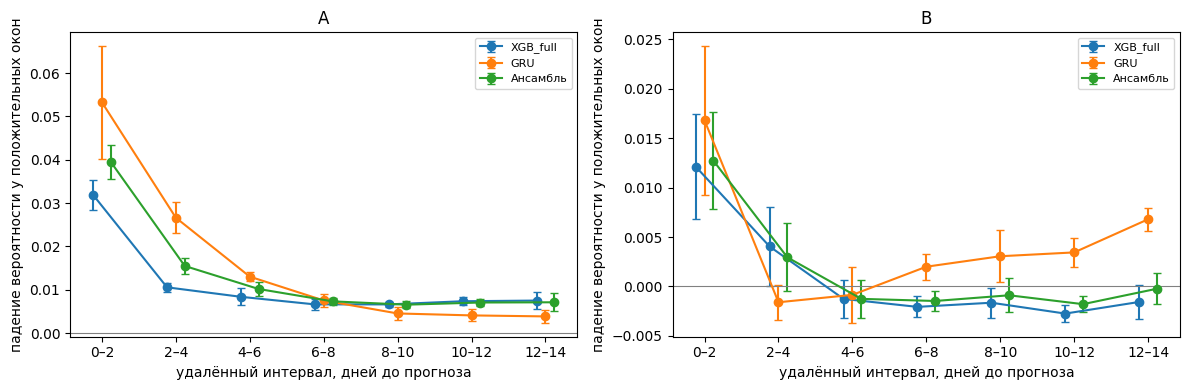

In [7]:
time_tabs = {}
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4), sharey=False)
for ax, t in zip(np.atleast_1d(axes), TARGETS):
    oc = pd.DataFrame(records[t]['occl'])
    agg = oc.groupby(['model', 'bin'])[['dp_pos', 'd_auprc']].agg(['mean', 'std'])
    ig_t = pd.concat(records[t]['gru_ig_time'], axis=1).mean(1)
    piv = oc.groupby(['bin', 'model'])['dp_pos'].mean().unstack().reindex(BIN_LABELS)
    time_tabs[t] = (agg, ig_t, piv)
    agg.to_csv(os.path.join(OUT, f'occlusion_{t}.csv'))
    xb = np.arange(len(BIN_LABELS))
    for j, m in enumerate(['XGB_full', 'GRU', 'Ансамбль']):
        sub = oc[oc.model == m].groupby('bin')['dp_pos']
        mean, sdv = sub.mean().reindex(BIN_LABELS), sub.std().reindex(BIN_LABELS)
        ax.errorbar(xb + (j - 1) * 0.12, mean, yerr=sdv, fmt='o-', capsize=3, label=m)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(xb, BIN_LABELS)
    ax.set_xlabel('удалённый интервал, дней до прогноза')
    ax.set_ylabel('падение вероятности у положительных окон')
    ax.set_title(t)
    ax.legend(fontsize=8)
    print(f'\n=== {t}: окклюзия (среднее по фолдам) ===')
    display(piv.round(4))
    print('Доля |IG| GRU по интервалам:', ig_t.round(3).to_dict())
    print(f"τ(окклюзия XGB, окклюзия GRU) = {kendall(piv['XGB_full'], piv['GRU']):.2f}; "
          f"τ(окклюзия GRU, IG GRU) = {kendall(piv['GRU'], ig_t):.2f}")
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'occlusion.png'), dpi=200, bbox_inches='tight')
plt.show()

## Проверка адекватности объяснений (Adebayo et al., 2018)

1. **GRU со случайными весами:** IG должна давать другие карты важности, чем у обученной модели.
2. **XGBoost, обученный на перемешанных метках:** ранжирование групп по SHAP должно перестать совпадать с настоящим.
   Если совпадение остаётся заметным, часть «важности» по SHAP объясняется устройством признаков (много различных значений, тяжёлые хвосты), а не выученной связью с исходом — поэтому SHAP проверяется перестановкой, которая измеряет реальное падение качества.

Фолд 0, цель A.

In [8]:
t, k = 'A', 0
tr, va, te = fold_masks(win, k)
add_phenotype_columns(win, pheno_win, k)
idx = samples[(t, k)][:1000]
gm, mu, sd, corr = load_gru(t, k)
ig_real = integrated_gradients(gm, X_seq[idx], seq_len[idx], mu, sd)
torch.manual_seed(SEED)
g_rand = GRUAttn(5)
ig_rand = integrated_gradients(g_rand, X_seq[idx], seq_len[idx], mu, sd)
rho = []
for i in range(len(idx)):
    m = seq_mask(seq_len[idx][i:i + 1])[0]
    a, b = np.abs(ig_real[i][m]).ravel(), np.abs(ig_rand[i][m]).ravel()
    rho.append(stats.spearmanr(a, b).statistic)
ch_real = pd.Series({c: np.abs(ig_real[:, :, chs]).sum() for c, chs in GRU_CHANNELS.items()})
ch_rand = pd.Series({c: np.abs(ig_rand[:, :, chs]).sum() for c, chs in GRU_CHANNELS.items()})
print(f'GRU: корреляция Спирмена карт IG (обученная vs случайная) = {np.nanmean(rho):.2f} (медиана {np.nanmedian(rho):.2f})')
print('  доли каналов, обученная:', (ch_real / ch_real.sum()).round(3).to_dict())
print('  доли каналов, случайная:', (ch_rand / ch_rand.sum()).round(3).to_dict())

y = win[f'y_{t}'].values
X_all = win[FULL].values.astype(float)
rng = np.random.default_rng(SEED)
m_shuf = fit_xgb(X_all[tr], rng.permutation(y[tr]), X_all[va], rng.permutation(y[va]), SEED)
sv_shuf = xgb_contribs(m_shuf, X_all[idx])
g_shuf = group_share(np.abs(sv_shuf).mean(0))
g_real = records[t]['xgb_shap'][k]
print(f'XGBoost на перемешанных метках: AUPRC на тесте = '
      f'{average_precision_score(y[te], m_shuf.predict_proba(X_all[te])[:, 1]):.3f} (доля событий {y[te].mean():.3f})')
print(f'  τ Кендалла групп SHAP (настоящая vs перемешанные метки) = {kendall(g_real, g_shuf):.2f}')
sanity = pd.DataFrame({'настоящая модель': g_real, 'перемешанные метки': g_shuf}).sort_values('настоящая модель', ascending=False)
sanity.to_csv(os.path.join(OUT, 'sanity_xgb_A.csv'))
display(sanity.round(3))

GRU: корреляция Спирмена карт IG (обученная vs случайная) = 0.15 (медиана 0.14)
  доли каналов, обученная: {'САД': 0.48500001430511475, 'ДАД': 0.1340000033378601, 'ЧП': 0.11599999666213989, 'Время измерений': 0.26600000262260437}
  доли каналов, случайная: {'САД': 0.0430000014603138, 'ДАД': 0.31299999356269836, 'ЧП': 0.32600000500679016, 'Время измерений': 0.3179999887943268}


XGBoost на перемешанных метках: AUPRC на тесте = 0.097 (доля событий 0.047)
  τ Кендалла групп SHAP (настоящая vs перемешанные метки) = 0.53


,настоящая модель,перемешанные метки
История КЗС,0.381,0.263
САД: пики,0.181,0.036
ЧП,0.110,0.099
ДАД,0.074,0.147
САД: уровень,0.061,0.067
Пациент,0.048,0.124
САД: вариабельность,0.041,0.140
Пульсовое давление,0.033,0.040
Режим измерений,0.031,0.028
САД: динамика,0.029,0.035


## Привязка к физиологии: частота событий по децилям признаков (без модели)

Если модель опирается на признак, связь должна быть видна и в самих данных. Для каждого признака окна делятся на децили, и считается доля окон, после которых было событие.

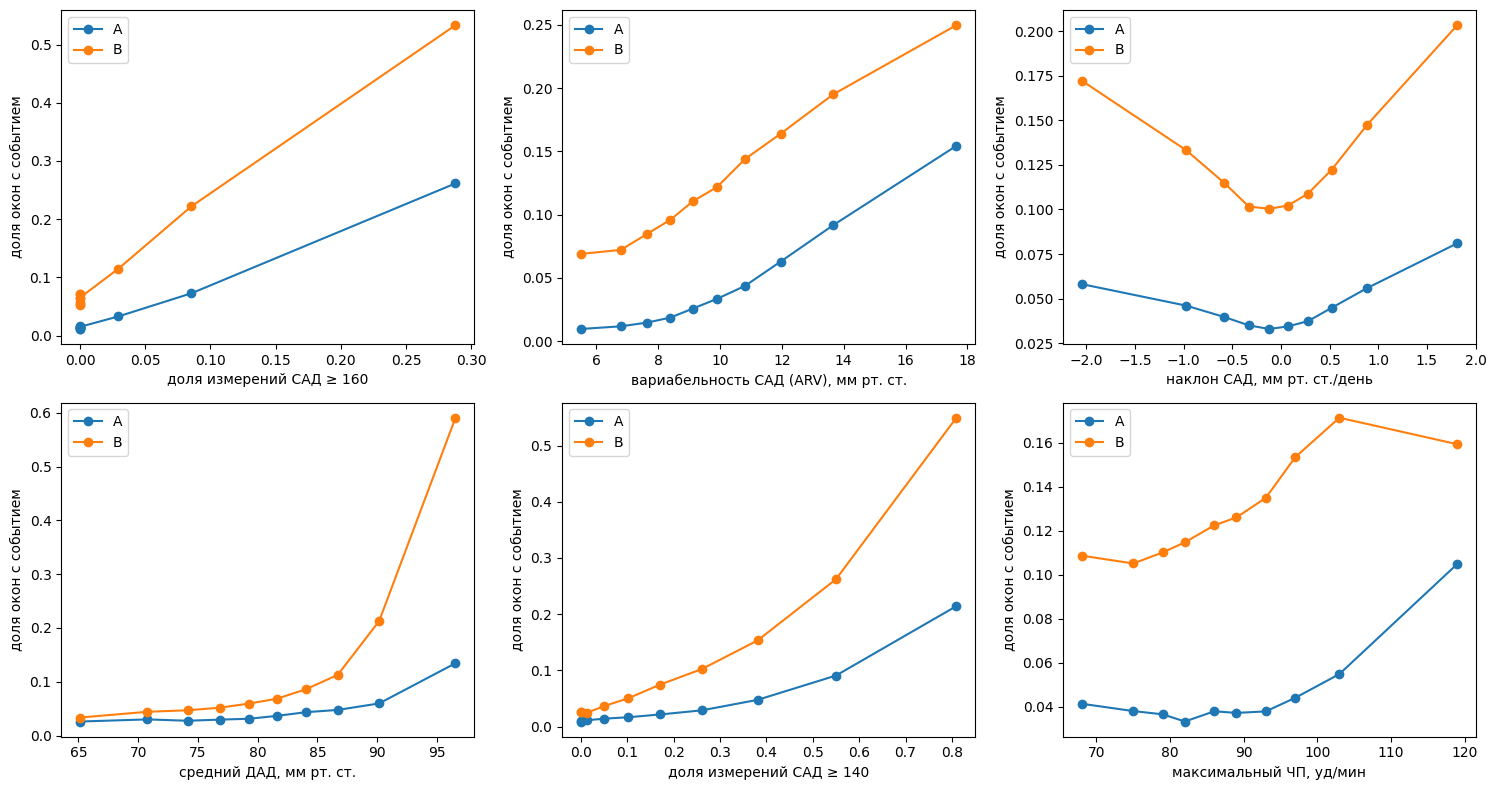

,признак,цель,частота в 1-м дециле,частота в 10-м дециле,отношение 10/1,ρ Спирмена
0,доля измерений САД ≥ 160,A,0.016,0.262,16.262,0.280
1,доля измерений САД ≥ 160,B,0.072,0.533,7.456,0.354
2,"вариабельность САД (ARV), мм рт. ст.",A,0.010,0.154,16.222,0.183
3,"вариабельность САД (ARV), мм рт. ст.",B,0.069,0.250,3.625,0.158
4,"наклон САД, мм рт. ст./день",A,0.058,0.081,1.393,0.026
5,"наклон САД, мм рт. ст./день",B,0.172,0.203,1.181,0.023
6,"средний ДАД, мм рт. ст.",A,0.026,0.135,5.173,0.114
7,"средний ДАД, мм рт. ст.",B,0.033,0.591,17.674,0.349
8,доля измерений САД ≥ 140,A,0.009,0.214,23.287,0.224
9,доля измерений САД ≥ 140,B,0.026,0.549,21.543,0.380


In [9]:
PHYS = [('frac160', 'доля измерений САД ≥ 160'), ('sbp_arv', 'вариабельность САД (ARV), мм рт. ст.'),
        ('sbp_slope', 'наклон САД, мм рт. ст./день'), ('dbp_mean', 'средний ДАД, мм рт. ст.'),
        ('tir140', 'доля измерений САД ≥ 140'), ('hr_max', 'максимальный ЧП, уд/мин')]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
phys_rows = []
for ax, (col, label) in zip(axes.ravel(), PHYS):
    v = win[col].values
    ok = ~np.isnan(v)
    q = pd.qcut(pd.Series(v[ok]).rank(method='first'), 10, labels=False)
    for t in TARGETS:
        yy = win[f'y_{t}'].values[ok]
        rate = pd.Series(yy).groupby(q.values).mean()
        mid = pd.Series(v[ok]).groupby(q.values).median()
        ax.plot(mid.values, rate.values, 'o-', label=t)
        rs = stats.spearmanr(v[ok], yy).statistic
        phys_rows.append({'признак': label, 'цель': t, 'частота в 1-м дециле': rate.iloc[0],
                          'частота в 10-м дециле': rate.iloc[-1], 'отношение 10/1': rate.iloc[-1] / max(rate.iloc[0], 1e-9),
                          'ρ Спирмена': rs})
    ax.set_xlabel(label)
    ax.set_ylabel('доля окон с событием')
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT, 'physiology_deciles.png'), dpi=200, bbox_inches='tight')
plt.show()
phys = pd.DataFrame(phys_rows)
phys.to_csv(os.path.join(OUT, 'physiology_deciles.csv'), index=False)
display(phys.round(3))

## Локальная интерпретация: разборы отдельных окон (фолд 0)

Для каждой цели — четыре окна из тестовой выборки:
- верно предсказанное событие у пациента **без событий этого типа в прошлом** (модель должна опираться на давление, а не на историю);
- верно предсказанное событие с наибольшей вероятностью;
- пропущенное событие;
- ложная тревога.

Графики сохраняются в `results_v2/interpret/local_cases_*.png` (в git не попадают: это данные отдельных пациентов). Слева — траектория САД/ДАД за 30 дней до прогноза и горизонт прогноза (серым), цвет точек — |IG| GRU для последних 20 измерений. Справа — 8 крупнейших вкладов SHAP в прогноз XGB_full.

In [10]:
NAMES = {'ev_A_days_since': 'дней с последнего события A', 'ev_A_14': 'событий A за 14 дн.', 'ev_A_7': 'событий A за 7 дн.',
         'ev_B_days_since': 'дней с последнего события B', 'ev_B_14': 'событий B за 14 дн.', 'ev_B_7': 'событий B за 7 дн.',
         'ev_OLD_days_since': 'дней с последнего события OLD', 'ev_ALL_days_since': 'дней с последнего КЗС',
         'ev_ALL_14': 'КЗС за 14 дн.', 'frac160': 'доля САД ≥ 160', 'frac180': 'доля САД ≥ 180', 'tir140': 'доля САД ≥ 140',
         'sbp_max': 'макс. САД', 'sbp_mean': 'средний САД', 'sbp_last': 'последний САД', 'sbp_arv': 'ARV САД',
         'sbp_slope': 'наклон САД', 'dbp_mean': 'средний ДАД', 'dbp_frac90': 'доля ДАД ≥ 90', 'hr_max': 'макс. ЧП',
         'hr_mean': 'средний ЧП', 'n_meas': 'число измерений', 'days_in_program': 'дней в программе', 'age': 'возраст',
         'ev_OLD_14': 'событий OLD за 14 дн.', 'ev_OLD_7': 'событий OLD за 7 дн.', 'ev_B_days_since': 'дней с последнего события B',
         'ev_ALL_7': 'КЗС за 7 дн.', 'sbp_last3d_minus_prev': 'САД: 3 посл. дня минус ранее', 'sbp_min': 'мин. САД',
         'sbp_std': 'SD САД', 'dbp_arv': 'ARV ДАД', 'dbp_max': 'макс. ДАД', 'dbp_last': 'последний ДАД',
         'dbp_min': 'мин. ДАД', 'dbp_slope': 'наклон ДАД', 'dbp_std': 'SD ДАД', 'hr_last': 'последний ЧП',
         'hr_min': 'мин. ЧП', 'hr_std': 'SD ЧП', 'hr_arv': 'ARV ЧП', 'hr_slope': 'наклон ЧП', 'pp_mean': 'пульсовое давление',
         'pp_std': 'SD пульсового давления', 'n_days': 'дней с измерениями', 'days_since_last_meas': 'дней с последнего измерения',
         'bmi': 'ИМТ', 'cluster': 'фенотип GDTW', 'pd0': 'расстояние до фенотипа 0', 'pd1': 'расстояние до фенотипа 1',
         'pd2': 'расстояние до фенотипа 2', 'grp_experience': 'группа «опыт»', 'grp_control': 'группа «контроль»'}


def pick_cases(t, k=0):
    idx = samples[(t, k)]
    y = win[f'y_{t}'].values[idx]
    s = oof_v2[f'{t}__XGB_full__score'].values[idx]
    pred = oof_v2[f'{t}__XGB_full__pred'].values[idx]
    first = np.isnan(win[f'ev_{t}_days_since'].values[idx])
    cases = {}
    tp_first = np.flatnonzero((y == 1) & (pred == 1) & first)
    if len(tp_first):
        cases['верный прогноз, первое событие'] = tp_first[np.argmax(s[tp_first])]
    tp = np.flatnonzero((y == 1) & (pred == 1))
    cases['верный прогноз, макс. вероятность'] = tp[np.argmax(s[tp])]
    fn = np.flatnonzero((y == 1) & (pred == 0))
    cases['пропущенное событие'] = fn[np.argmin(s[fn])]
    fp = np.flatnonzero((y == 0) & (pred == 1))
    cases['ложная тревога'] = fp[np.argmax(s[fp])]
    return {name: (j, idx[j]) for name, j in cases.items()}


case_rows = []
for t in TARGETS:
    cfg_gap = {'A': 1, 'B': 7}[t]
    codes = {'A': [33012, 33901, 33902], 'B': [33601, 33801, 33802, 33810, 33911]}[t]
    ig0 = np.load(os.path.join(CACHE_DIR, f'ig_{t}_fold0.npy'))
    sv0 = np.load(os.path.join(CACHE_DIR, f'shap_{t}_fold0.npy'))
    cases = pick_cases(t)
    fig, axes = plt.subplots(len(cases), 2, figsize=(15, 3.6 * len(cases)), gridspec_kw={'width_ratios': [2.2, 1]})
    for row, (name, (j, i)) in enumerate(cases.items()):
        r = win.iloc[i]
        a, b = PAT[int(r['pid'])]
        cut = r['cut']
        sel = (TD[a:b] >= cut - 30) & (TD[a:b] < cut + cfg_gap + 7)
        td = TD[a:b][sel] - cut
        ax = axes[row, 0]
        ax.axvspan(cfg_gap, cfg_gap + 7, color='0.9', label='горизонт прогноза')
        ax.axvspan(-14, 0, color='#e8f0fb', label='окно истории')
        ax.plot(td, S[a:b][sel], '.-', color='#c0392b', lw=0.8, ms=3, label='САД')
        ax.plot(td, D[a:b][sel], '.-', color='#2471a3', lw=0.8, ms=3, label='ДАД')
        L = int(seq_len[i])
        days = -X_seq[i, MAX_POINTS - L:, 3]
        imp = np.abs(ig0[j, MAX_POINTS - L:, :]).sum(1)
        sc = ax.scatter(days, X_seq[i, MAX_POINTS - L:, 0], c=imp, cmap='YlOrBr', s=40, zorder=3, edgecolor='k', lw=0.3)
        ev = events[(events.pid == r['pid']) & events.code.isin(codes)]
        evd = ev['td'].values - cut
        evd = evd[(evd >= -30) & (evd < cfg_gap + 7)]
        for e in evd:
            ax.axvline(e, color='k', lw=0.6, ls=':')
        ax.set_title(f"{t}: {name} (p = {oof_v2[f'{t}__XGB_full__score'].values[i]:.2f}, "
                     f"событие {'было' if win[f'y_{t}'].values[i] else 'не было'})", fontsize=10)
        ax.set_xlabel('дни относительно момента прогноза (пунктир — события типа ' + t + ')')
        ax.set_ylabel('мм рт. ст.')
        if row == 0:
            ax.legend(fontsize=7, loc='upper left')
        top = np.argsort(-np.abs(sv0[j]))[:8][::-1]
        axes[row, 1].barh([f"{NAMES.get(FULL[c], FULL[c])} = {win.iloc[i][FULL[c]]:.3g}" for c in top],
                          sv0[j][top], color=['#c0392b' if v > 0 else '#2471a3' for v in sv0[j][top]])
        axes[row, 1].axvline(0, color='k', lw=0.6)
        axes[row, 1].set_xlabel('вклад SHAP в logit')
        case_rows.append({'цель': t, 'случай': name, 'p': oof_v2[f'{t}__XGB_full__score'].values[i],
                          'событие': int(win[f'y_{t}'].values[i]),
                          'топ-3 вклада': '; '.join(f"{NAMES.get(FULL[c], FULL[c])} ({sv0[j][c]:+.2f})"
                                                    for c in np.argsort(-np.abs(sv0[j]))[:3])})
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, f'local_cases_{t}.png'), dpi=170, bbox_inches='tight')
    plt.close(fig)   # траектории отдельных пациентов — только в файл, не в вывод ноутбука
cases_df = pd.DataFrame(case_rows)
cases_df.to_csv(os.path.join(OUT, 'local_cases.csv'), index=False)
display(cases_df.round(3))

,цель,случай,p,событие,топ-3 вклада
0,A,"верный прогноз, первое событие",0.271,1,доля САД ≥ 160 (+1.30); дней с последнего собы...
1,A,"верный прогноз, макс. вероятность",0.908,1,дней с последнего события A (+1.78); доля САД ...
2,A,пропущенное событие,0.003,1,дней с последнего события A (-0.92); доля САД ...
3,A,ложная тревога,0.829,0,дней с последнего события A (+1.71); доля САД ...
4,B,"верный прогноз, первое событие",0.453,1,средний ДАД (+0.98); дней с последнего события...
5,B,"верный прогноз, макс. вероятность",0.976,1,средний ДАД (+1.22); дней с последнего события...
6,B,пропущенное событие,0.002,1,дней с последнего события B (-0.96); число изм...
7,B,ложная тревога,0.923,0,средний ДАД (+1.25); дней с последнего события...
